# 10 · The 2017 evaluation

The organisers' evaluator (`evaluation/evaluate.py`) replays the 2017 requests through a `Solution` and prints the net revenue.
It was run on the shipped solution and on the two baselines. This notebook only reads the recorded results: the recipe was chosen
on the 2016 replay and the temporal walk-forward, 2017 was not used to choose or tune anything, and `evaluation/run.py` reproduces
the three numbers exactly. They are what the evaluator prints when run locally on this repository, not a score announced by the
organisers.

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src import plotting as P

P.setup()
EV = Path("..") / "evaluation"
res = pd.read_csv(EV / "results.csv")
pd.options.display.float_format = "{:,.0f}".format

## 1 · The solution that was evaluated

In [2]:
m = json.loads((EV / "freeze_manifest.json").read_text())
print(f"Hashes written at {m['created_utc']} UTC (Python {m['python']})")
pd.Series({k: v[:16] for k, v in m["files"].items() if k in ("solution.py", "models/final.joblib", "src/policy.py", "src/stream_model.py")},
          name="sha256 (first 16 hex)").to_frame()

Hashes written at 2026-11-16T12:33:14+00:00 UTC (Python 3.14.7)


,sha256 (first 16 hex)
solution.py,496f87f509fe6a0b
models/final.joblib,97d47f08bc204fe3
src/policy.py,65af03d806cbadea
src/stream_model.py,ebeaf567a45e256a


## 2 · The evaluator run

In [3]:
ev = res.set_index("solution").net_revenue_eur
names = {"no_overbooking": "No overbooking", "average_rate": "Classic overbooking", "model": "This system"}
tab = ev.rename(index=names).to_frame("net revenue 2017 (EUR)")
mine, avg, none = ev["model"], ev["average_rate"], ev["no_overbooking"]
print(f"This system: EUR {mine:,.0f}")
print(f"  vs classic overbooking: {mine / avg - 1:+.1%}  (EUR {mine - avg:,.0f} more)")
print(f"  vs no overbooking:      {mine / none - 1:+.1%}  (EUR {mine - none:,.0f} more)")
tab

This system: EUR 5,425,157
  vs classic overbooking: +29.4%  (EUR 1,231,894 more)
  vs no overbooking:      +72.3%  (EUR 2,276,123 more)


,net revenue 2017 (EUR)
solution,
No overbooking,3149034
Classic overbooking,4193263
This system,5425157


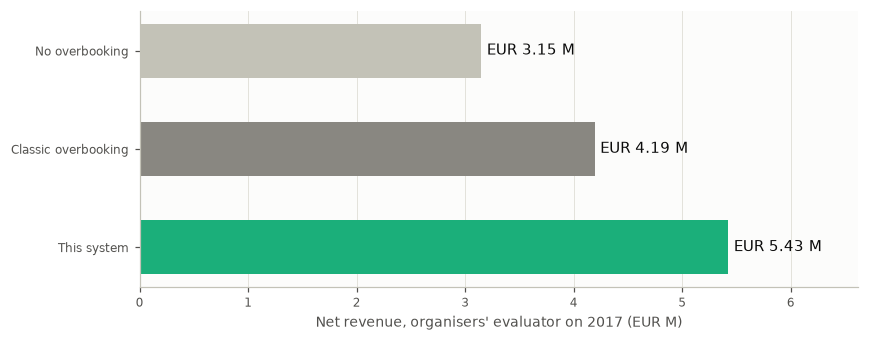

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.2))
v = ev.rename(index=names)[["No overbooking", "Classic overbooking", "This system"]] / 1e6
bars = ax.barh(v.index[::-1], v.values[::-1], color=[P.OURS, P.REFERENCE, P.REFERENCE_LIGHT], height=0.55)
for b, x in zip(bars, v.values[::-1]):
    ax.text(x + 0.05, b.get_y() + b.get_height() / 2, f"EUR {x:.2f} M", va="center")
ax.set_xlim(0, v.max() * 1.22); ax.set_xlabel("Net revenue, organisers' evaluator on 2017 (EUR M)"); ax.grid(axis="y", visible=False)
P.save(fig, "evaluator_2017")
plt.tight_layout(); plt.show()

## 3 · Against the local replay of 2016

Same rules, models trained on the past only. Not directly comparable (another year, and the evaluator orders same-day
requests by `booking_id`), but the order of the three solutions is the same.

In [5]:
local = pd.Series({"No overbooking": 3.790, "Classic overbooking": 5.257, "This system": 6.328})
off = ev.rename(index=names) / 1e6
cmp = pd.DataFrame({"2016 local replay (EUR M)": local, "2017 evaluator (EUR M)": off})
cmp["gain vs classic, 2016 (%)"] = (cmp.iloc[:, 0] / local["Classic overbooking"] - 1) * 100
cmp["gain vs classic, 2017 (%)"] = (cmp.iloc[:, 1] / off["Classic overbooking"] - 1) * 100
cmp.loc[["No overbooking", "Classic overbooking", "This system"]].round(2)

,2016 local replay (EUR M),2017 evaluator (EUR M),"gain vs classic, 2016 (%)","gain vs classic, 2017 (%)"
No overbooking,4,3,-28,-25
Classic overbooking,5,4,0,0
This system,6,5,20,29


The gain over classic overbooking is +20% on the 2016 replay and +29% on the 2017 evaluator run: the 2017 test year was kinder to the
bid-price policy than 2016 was, and one year cannot say how much of that is luck.

## 4 · Limits

- The evaluator prints only the net revenue: there is no figure for walked guests or occupied room-nights.
- "Perfect foresight" needs the 2017 outcomes, so it cannot come from the evaluator run.
- The model was not changed after the run; the evaluation kit is in the repository for reporting only.